# 1. Imports


In [91]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

# 2. Path config


In [117]:

ROOT = Path.cwd().parent.parent.parent
DATA_DIR = ROOT / "data"
print(ROOT)
print(DATA_DIR)

/home/samuel/projects/machine-learning-from-scratch
/home/samuel/projects/machine-learning-from-scratch/data


# 3. Load data

In [120]:
df = pd.read_csv(DATA_DIR / "API_NY.GDP.PCAP.CD_DS2_en_csv_v2_1529.csv")
# gdp_df.rename(columns={"Entity": "country_name", "Year": "year", "GDP per capita": "GDP_per_capita"}, inplace=True)

In [121]:
# Remove unnecessary columns
df = df.drop(columns=["Unnamed: 70"], errors="ignore")

# Remove metadata columns that are not needed
df = df.drop(columns=["Indicator Name", "Indicator Code"])

# Rename columns
df = df.rename(columns={
    "Country Name": "country",
    "Country Code": "country_code"
})

# Remove rows without country information
df = df.dropna(subset=["country", "country_code"])

# Remove duplicate countries
df = df.drop_duplicates(subset=["country_code"])

In [122]:
df = df.melt(
    id_vars=["country", "country_code"],
    var_name="year",
    value_name="gdp_per_capita"
)

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["gdp_per_capita"] = pd.to_numeric(
    df["gdp_per_capita"],
    errors="coerce"
)

df = df.dropna(subset=["year", "gdp_per_capita"])

df["year"] = df["year"].astype(int)

df = df.sort_values(["country", "year"]).reset_index(drop=True)

In [125]:
df.head()

,country,country_code,year,gdp_per_capita
0,Afghanistan,AFG,2000,174.930991
1,Afghanistan,AFG,2001,138.706822
2,Afghanistan,AFG,2002,178.954088
3,Afghanistan,AFG,2003,198.871116
4,Afghanistan,AFG,2004,221.763654


# 4. Data exploration by country

In [126]:
def df_filtered_by_country(df, country):
    return df[df["country"] == country]

In [147]:
df_brazil = df_filtered_by_country(df, "Brazil")
df_portugal = df_filtered_by_country(df, "Portugal")

df_brazil.head()

,country,country_code,year,gdp_per_capita
1591,Brazil,BRA,1960,235.266010
1592,Brazil,BRA,1961,231.564063
1593,Brazil,BRA,1962,250.200573
1594,Brazil,BRA,1963,294.169619
1595,Brazil,BRA,1964,257.259727


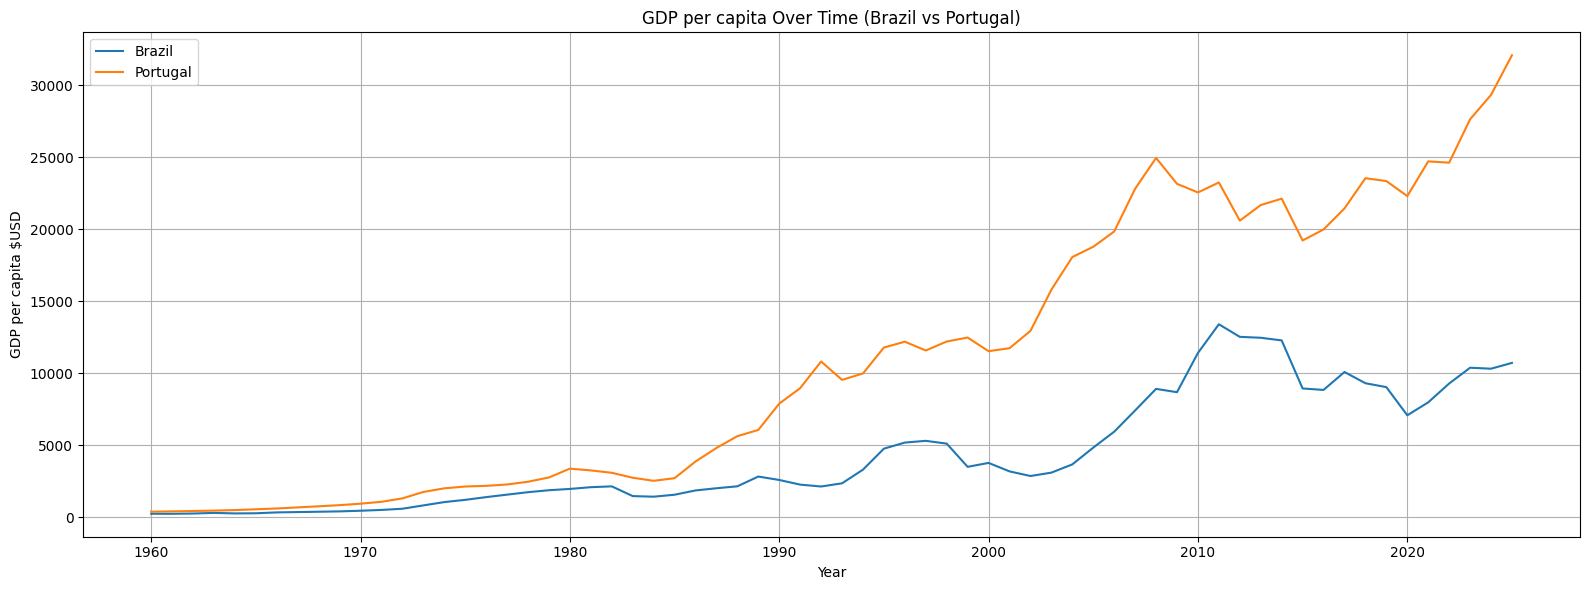

In [128]:
fig, ax = plt.subplots(figsize=(16, 6), dpi=100)

plt.plot(df_brazil["year"], df_brazil["gdp_per_capita"], label="Brazil")
plt.plot(df_portugal["year"], df_portugal["gdp_per_capita"], label="Portugal")
plt.xlabel("Year")
plt.ylabel("GDP per capita $USD")
plt.title("GDP per capita Over Time (Brazil vs Portugal)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [133]:
from sklearn.linear_model import LinearRegression

X_brazil = df_brazil["year"].values.reshape(-1, 1)
y_brazil = df_brazil["gdp_per_capita"].values

X_portugal = df_portugal["year"].values.reshape(-1, 1)
y_portugal = df_portugal["gdp_per_capita"].values

print("X_brazil.shape:", X_brazil.shape)
print("y_brazil.shape:", y_brazil.shape)
print("X_portugal.shape:", X_portugal.shape)
print("y_portugal.shape:", y_portugal.shape)

X_brazil.shape: (66, 1)
y_brazil.shape: (66,)
X_portugal.shape: (66, 1)
y_portugal.shape: (66,)


In [134]:
model_brazil = LinearRegression()
model_brazil.fit(X_brazil, y_brazil)

model_portugal = LinearRegression()
model_portugal.fit(X_portugal, y_portugal)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
future_years = np.arange(2026, 2029).reshape(-1, 1)
future_predictions_brazil = model_brazil.predict(future_years)
future_predictions_portugal = model_portugal.predict(future_years)

print("Future predictions (Brazil):")
for year, prediction in zip(future_years.flatten(), future_predictions_brazil):
    print(f"Year: {year}, Predicted GDP per capita (Brazil): {prediction:.2f}")

print("Future predictions (Portugal):")
for year, prediction in zip(future_years.flatten(), future_predictions_portugal):
    print(f"Year: {year}, Predicted GDP per capita (Portugal): {prediction:.2f}")

Future predictions (Brazil):
Year: 2026, Predicted GDP per capita (Brazil): 10483.85
Year: 2027, Predicted GDP per capita (Brazil): 10667.31
Year: 2028, Predicted GDP per capita (Brazil): 10850.78
Future predictions (Portugal):
Year: 2026, Predicted GDP per capita (Portugal): 27015.66
Year: 2027, Predicted GDP per capita (Portugal): 27492.95
Year: 2028, Predicted GDP per capita (Portugal): 27970.24


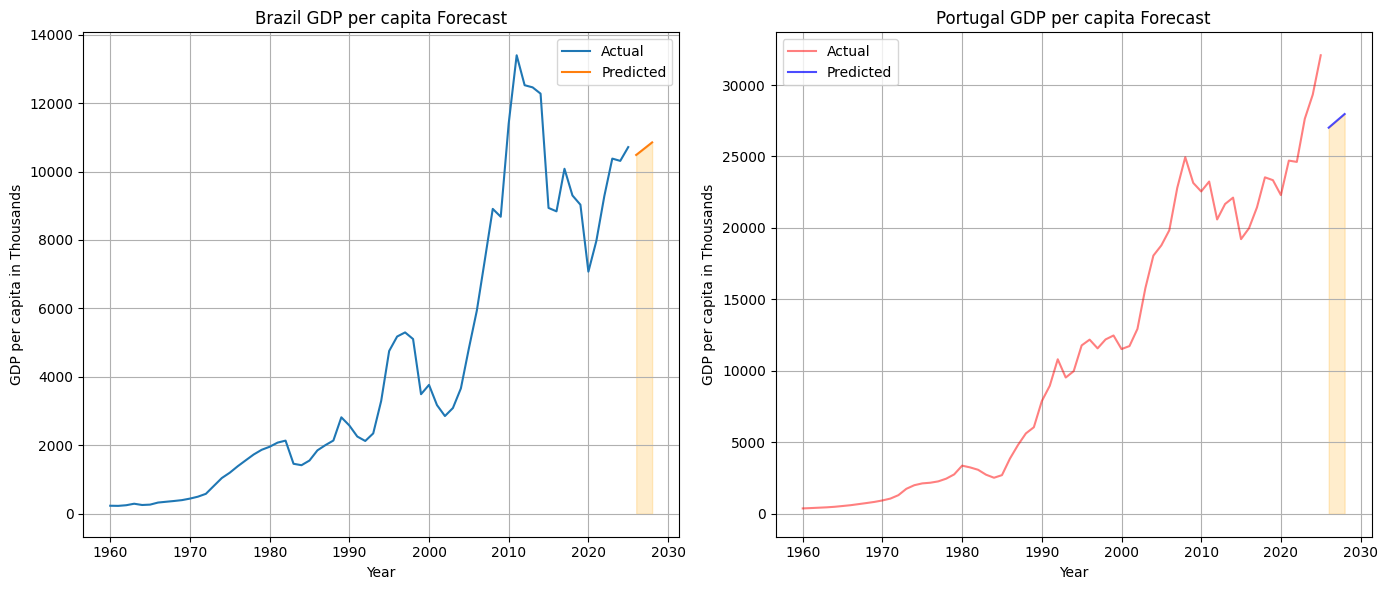

In [ ]:
# Visualize future predictions
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), dpi=100)
ax[0].plot(df_brazil["year"], df_brazil["gdp_per_capita"], label="Actual")
ax[0].plot(future_years, future_predictions_brazil, label="Predicted", linestyle="-")
ax[0].fill_between(future_years.flatten(), future_predictions_brazil, alpha=0.2, color='orange')
ax[0].set_xlabel("Year")
ax[0].set_ylabel("GDP per capita in Thousands")
ax[0].set_title("Brazil GDP per capita Forecast")
ax[0].grid(True)
ax[0].legend()

ax[1].plot(df_portugal["year"], df_portugal["gdp_per_capita"], label="Actual", color='red', alpha=0.5)
ax[1].plot(future_years, future_predictions_portugal, label="Predicted", linestyle="-", color='blue', alpha=0.7)
ax[1].fill_between(future_years.flatten(), future_predictions_portugal, alpha=0.2, color='orange')
ax[1].set_xlabel("Year")
ax[1].set_ylabel("GDP per capita in Thousands")
ax[1].set_title(f"Portugal GDP per capita Forecast for the {len(future_years)} next years")
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()